In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import math
device = "cuda"
print(torch.cuda.get_device_name(0))

Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 44.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.23MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.01MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.88MB/s]


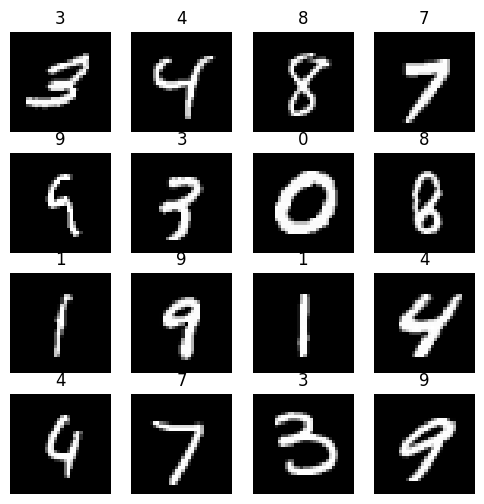

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Pad(2), 
    transforms.Lambda(lambda x: x * 2 - 1)
])
ds = datasets.MNIST(root = "/kaggle/temp/mnist", transform = transform, download = True)
img, label = ds[0]
loader = DataLoader(ds, batch_size = 128, shuffle = True)
x, y = next(iter(loader))
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i in range(16):
    ax = axes.flatten()[i]
    ax.imshow(x[i, 0], cmap = "gray")
    ax.set_title(y[i].item())
    ax.axis("off")
plt.show()

tensor(0.5473)
tensor(0.6197)
tensor(0.7374)
tensor(0.8373)
tensor(0.9256)
tensor(1.0049)
tensor(1.0401)


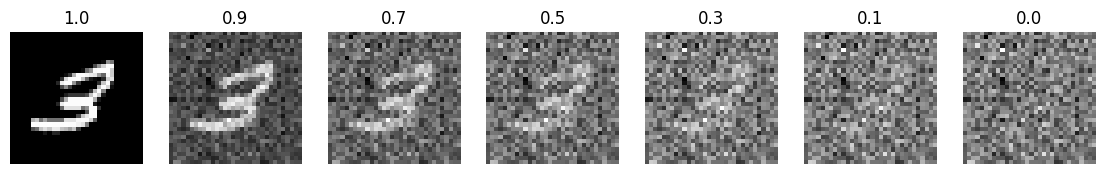

In [3]:
clean = x[0]
noise = torch.randn_like(clean)
fig, axes = plt.subplots(1, 7, figsize=(14, 2))
for i, a in enumerate([1.0, 0.9, 0.7, 0.5, 0.3, 0.1, 0.0]):
    noisy = math.sqrt(a) * clean + math.sqrt(1 - a) * noise
    axes[i].imshow(noisy[0], cmap = "gray")
    axes[i].set_title(a)
    axes[i].axis("off")
    print(noisy.std())
plt.show()

tensor(0.9999) tensor(0.0786) tensor(4.0358e-05)


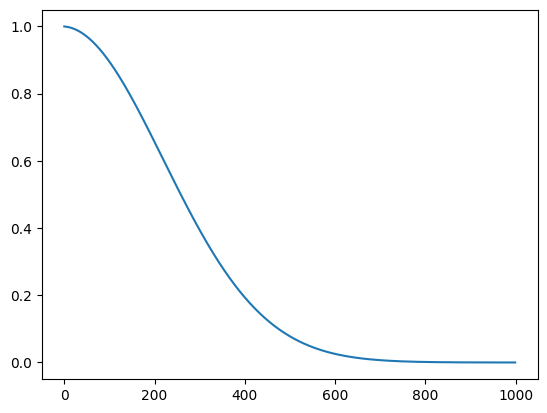

In [4]:
T = 1000
betas = torch.linspace(0.0001, 0.02, T)
alphas = 1 - betas
alpha_bar =  torch.cumprod(alphas, dim = 0)
print(alpha_bar[0], alpha_bar[499], alpha_bar[999])
plt.plot(alpha_bar)
plt.show()

torch.Size([8, 1, 32, 32])


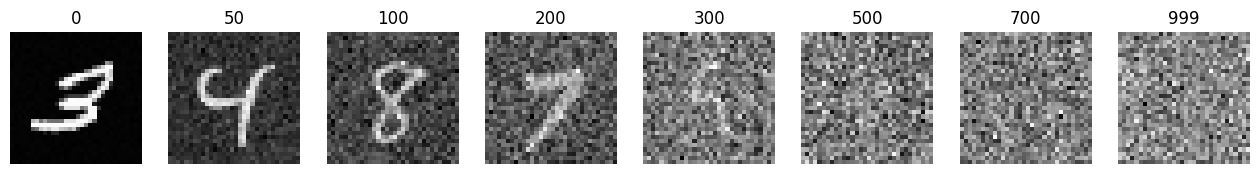

In [5]:
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = alpha_bar[t]
    a = a.view(-1, 1, 1, 1)
    noisy = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * noise
    return noisy, noise
t = torch.tensor([0, 50, 100, 200, 300, 500, 700, 999])
noisy, noise = add_noise(x[:8], t)
print(noisy.shape)
fig, axes = plt.subplots(1, 8, figsize = (16, 2))
for i in range(8):
    axes[i].imshow(noisy[i, 0], cmap = "gray")
    axes[i].set_title(t[i].item())
    axes[i].axis("off")
plt.show()

torch.Size([4, 32])


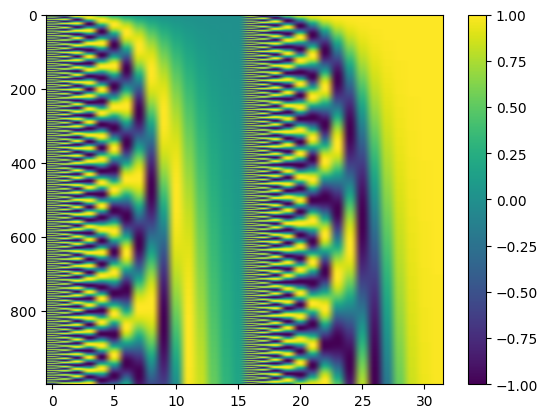

In [6]:
def time_embedding(t, dim = 32):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim = 1)

e = time_embedding(torch.tensor([0, 1, 500, 999]))
print(e.shape)
e_all = time_embedding(torch.arange(T))
plt.imshow(e_all, aspect = "auto")
plt.colorbar()
plt.show()

In [7]:
class TinyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size = 3, padding = 1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size = 3, padding = 1, stride = 2)
        self.conv3 = nn.Conv2d(32, 1, kernel_size = 3, padding = 1)
        self.act = nn.SiLU()
        self.up = nn.Upsample(scale_factor = 2)
    def forward(self, k):
        h = self.conv1(k)
        h = self.act(h)
        h = self.conv2(h)
        h = self.act(h)
        h = self.up(h)
        h = self.conv3(h)
        return h
model = TinyNet()

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim = 32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size = 3, padding = 1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size = 3, padding = 1)
        self.act = nn.SiLU()
        self.t_proj = nn.Linear(t_dim, out_ch)
    def forward(self, x, t_emb):
        h = self.conv1(x)
        h = self.act(h)
        tt = self.t_proj(t_emb)
        tt = tt[:, :, None, None]
        h = h + tt
        h = self.conv2(h)
        h = self.act(h)
        return h

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = Block(1, 32)
        self.down1 = nn.Conv2d(32, 32, kernel_size = 3, stride = 2, padding = 1)
        self.block2 = Block(32, 64)
        self.down2 = nn.Conv2d(64, 64, kernel_size = 3, stride = 2, padding = 1)
        self.mid = Block(64, 128)
        self.up = nn.Upsample(scale_factor = 2)
        self.block3 = Block(192, 64)
        self.block4 = Block(96, 32)
        self.out = nn.Conv2d(32, 1, kernel_size = 1)
    def forward(self, x, t):
        t_emb = time_embedding(t)
        d1 = self.block1(x, t_emb)
        h = self.down1(d1)
        d2 = self.block2(h, t_emb)
        h = self.down2(d2)
        h = self.mid(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d2], dim = 1)
        h = self.block3(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d1], dim = 1)
        h = self.block4(h, t_emb)
        return self.out(h)

model = UNet()
t = torch.randint(0, T, (8,))
print(model(x[:8], t).shape)                           # → [8, 1, 32, 32]
print(sum(p.numel() for p in model.parameters()))      # a bit more than 517,153

torch.Size([8, 1, 32, 32])
527713
